In [2]:
import glob, json, os, random
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, models, callbacks
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import IsolationForest
from sklearn.metrics import precision_score, recall_score, f1_score, roc_auc_score

SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)

WINDOW = 32        # samples per window (about 32 seconds)
TRAIN_STEP = 4     # overlap for training windows (more training data)
TEST_STEP = 1
PERCENTILE = 99    # threshold percentile

DATA = "../data/SKAB/data"
MODELS = "../models"
os.makedirs(MODELS, exist_ok=True)

In [3]:
def load(path):
    return pd.read_csv(path, sep=";", index_col="datetime", parse_dates=True)

normal = load(f"{DATA}/anomaly-free/anomaly-free.csv")
FEATURES = [c for c in normal.columns if c not in ("anomaly", "changepoint")]
print("Features:", len(FEATURES), FEATURES)

split = int(len(normal) * 0.8)                 # first 80% train, last 20% validation
train_raw = normal[FEATURES].iloc[:split].values
val_raw = normal[FEATURES].iloc[split:].values

scaler = StandardScaler().fit(train_raw)       # fit on train only
train_s = scaler.transform(train_raw)
val_s = scaler.transform(val_raw)
joblib.dump(scaler, f"{MODELS}/scaler.pkl")
print("Train rows:", len(train_s), "| Val rows:", len(val_s))

Features: 8 ['Accelerometer1RMS', 'Accelerometer2RMS', 'Current', 'Pressure', 'Temperature', 'Thermocouple', 'Voltage', 'Volume Flow RateRMS']
Train rows: 7524 | Val rows: 1881


In [4]:
def make_windows(arr, size, step):
    return np.array([arr[i:i + size].flatten()
                     for i in range(0, len(arr) - size + 1, step)])

X_train = make_windows(train_s, WINDOW, TRAIN_STEP)
X_val = make_windows(val_s, WINDOW, TRAIN_STEP)
INPUT_DIM = X_train.shape[1]                   # 32 x 8 = 256
print("Train windows:", X_train.shape, "| Val windows:", X_val.shape)

Train windows: (1874, 256) | Val windows: (463, 256)


Epoch 1/100
30/30 - 3s - 93ms/step - loss: 0.7317 - val_loss: 0.7883
Epoch 2/100
30/30 - 0s - 7ms/step - loss: 0.4799 - val_loss: 0.7218
Epoch 3/100
30/30 - 0s - 8ms/step - loss: 0.4648 - val_loss: 0.6565
Epoch 4/100
30/30 - 0s - 7ms/step - loss: 0.4523 - val_loss: 0.6175
Epoch 5/100
30/30 - 0s - 9ms/step - loss: 0.4412 - val_loss: 0.6035
Epoch 6/100
30/30 - 0s - 7ms/step - loss: 0.4322 - val_loss: 0.5905
Epoch 7/100
30/30 - 0s - 6ms/step - loss: 0.4244 - val_loss: 0.5763
Epoch 8/100
30/30 - 0s - 6ms/step - loss: 0.4170 - val_loss: 0.5586
Epoch 9/100
30/30 - 0s - 6ms/step - loss: 0.4107 - val_loss: 0.5525
Epoch 10/100
30/30 - 0s - 8ms/step - loss: 0.4050 - val_loss: 0.5402
Epoch 11/100
30/30 - 0s - 8ms/step - loss: 0.4004 - val_loss: 0.5348
Epoch 12/100
30/30 - 0s - 6ms/step - loss: 0.3957 - val_loss: 0.5305
Epoch 13/100
30/30 - 0s - 7ms/step - loss: 0.3912 - val_loss: 0.5198
Epoch 14/100
30/30 - 0s - 7ms/step - loss: 0.3870 - val_loss: 0.5126
Epoch 15/100
30/30 - 0s - 7ms/step - loss:

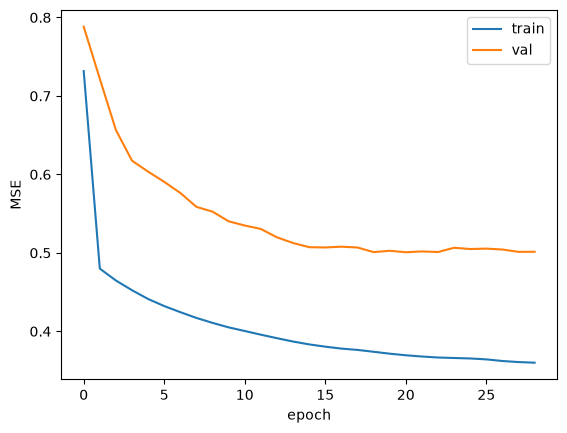

In [5]:
def build_autoencoder(input_dim):
    inp = layers.Input(shape=(input_dim,))
    x = layers.Dense(128, activation="relu")(inp)
    x = layers.Dense(64, activation="relu")(x)
    z = layers.Dense(16, activation="relu")(x)
    x = layers.Dense(64, activation="relu")(z)
    x = layers.Dense(128, activation="relu")(x)
    out = layers.Dense(input_dim, activation="linear")(x)
    return models.Model(inp, out)

ae = build_autoencoder(INPUT_DIM)
ae.compile(optimizer="adam", loss="mse")

history = ae.fit(
    X_train, X_train,
    validation_data=(X_val, X_val),
    epochs=100, batch_size=64, verbose=2,
    callbacks=[callbacks.EarlyStopping(patience=8, restore_best_weights=True)],
)
ae.save(f"{MODELS}/autoencoder.keras")

plt.plot(history.history["loss"], label="train")
plt.plot(history.history["val_loss"], label="val")
plt.xlabel("epoch"); plt.ylabel("MSE"); plt.legend(); plt.show()

AE threshold (99th percentile of validation error): 1.81370


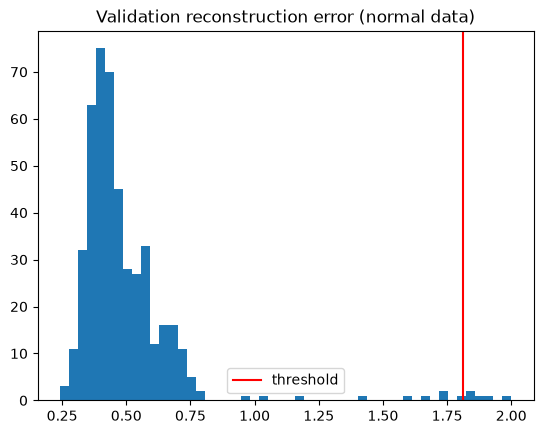

In [6]:
def recon_error(model, X):
    return np.mean((X - model.predict(X, verbose=0)) ** 2, axis=1)

val_err = recon_error(ae, X_val)
AE_THR = np.percentile(val_err, PERCENTILE)
print(f"AE threshold ({PERCENTILE}th percentile of validation error): {AE_THR:.5f}")

plt.hist(val_err, bins=50)
plt.axvline(AE_THR, color="red", label="threshold")
plt.title("Validation reconstruction error (normal data)")
plt.legend(); plt.show()

In [7]:
def make_labeled_windows(df, size, step):
    X = scaler.transform(df[FEATURES].values)
    y = df["anomaly"].values
    Xw, yw = [], []
    for i in range(0, len(X) - size + 1, step):
        Xw.append(X[i:i + size].flatten())
        yw.append(int(y[i:i + size].mean() > 0.5))
    return np.array(Xw), np.array(yw)

files = sorted(glob.glob(f"{DATA}/valve1/*.csv") + glob.glob(f"{DATA}/valve2/*.csv"))
Xs, ys = [], []
for f in files:
    Xw, yw = make_labeled_windows(load(f), WINDOW, TEST_STEP)
    Xs.append(Xw); ys.append(yw)

X_test = np.vstack(Xs)
y_test = np.concatenate(ys)
print("Test files:", len(files), "| Test windows:", X_test.shape)
print("Normal:", (y_test == 0).sum(), "| Anomaly:", (y_test == 1).sum())

Test files: 20 | Test windows: (21852, 256)
Normal: 14046 | Anomaly: 7806


In [8]:
def evaluate(name, scores, y, thr):
    pred = (scores > thr).astype(int)
    return {
        "Model": name,
        "Precision": precision_score(y, pred, zero_division=0),
        "Recall": recall_score(y, pred),
        "F1": f1_score(y, pred),
        "ROC-AUC": roc_auc_score(y, scores),
    }

ae_scores = recon_error(ae, X_test)
ae_result = evaluate("Autoencoder", ae_scores, y_test, AE_THR)
ae_result

{'Model': 'Autoencoder',
 'Precision': 0.35722130697419,
 'Recall': 1.0,
 'F1': 0.5264009710702002,
 'ROC-AUC': 0.592755205080164}

In [9]:
iso = IsolationForest(n_estimators=200, random_state=SEED, n_jobs=-1).fit(X_train)

iso_val = -iso.score_samples(X_val)            # higher = more anomalous
ISO_THR = np.percentile(iso_val, PERCENTILE)
iso_scores = -iso.score_samples(X_test)
iso_result = evaluate("Isolation Forest", iso_scores, y_test, ISO_THR)

results = pd.DataFrame([ae_result, iso_result]).round(3)
results

,Model,Precision,Recall,F1,ROC-AUC
0,Autoencoder,0.357,1.0,0.526,0.593
1,Isolation Forest,0.357,1.0,0.526,0.501


In [10]:
joblib.dump(iso, f"{MODELS}/isolation_forest.pkl")
config = {
    "window": WINDOW,
    "features": FEATURES,
    "ae_threshold": float(AE_THR),
    "iso_threshold": float(ISO_THR),
    "threshold_percentile": PERCENTILE,
}
json.dump(config, open(f"{MODELS}/config.json", "w"), indent=2)
results.to_csv(f"{MODELS}/model_comparison.csv", index=False)
print(os.listdir(MODELS))

['autoencoder.keras', 'config.json', 'isolation_forest.pkl', 'model_comparison.csv', 'scaler.pkl']
